In [6]:
%pip install torch torchvision scikit-learn pandas pillow pillow-heif

In [7]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -n -q "/content/drive/MyDrive/IE7615/IE7615 Deep Learning for"* -d /content/data
!cp "/content/drive/MyDrive/IE7615/split_manifest_v2.csv" /content/
!ls /content/data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
'IE7615 Deep Learning for AI'


In [8]:
import os, shutil, random, hashlib, time, copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, f1_score, accuracy_score
from PIL import Image
import pandas as pd

# ============ CONFIG (keep identical across ALL models) ============
SEED = 42
data_path = '/content/data/IE7615 Deep Learning for AI'  # <-- update this
output_dir = "dataset_split"
manifest_path = "split_manifest_v2.csv"  # NEW name: share this exact file with the MobileNetV2 + EfficientNet-B0 runs
train_ratio, val_ratio = 0.70, 0.15      # test = remaining 0.15
batch_size = 32
num_epochs = 10
VALID_EXT = ('.jpg', '.jpeg', '.png')    # HEIC dropped: PIL can't read it by default
EXCLUDE_BG = True                        # '_bg_' files are object-free backgrounds (YOLO negatives)
NEAR_DUP_THRESHOLD = 10                  # dHash Hamming distance (of 256 bits); 0 disables near-dup removal
FREEZE_BN = True                         # keep backbone BatchNorm in eval mode while training the head

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [9]:
# ============ STEP 1: Collect images, drop duplicates, set aside backgrounds ============
def file_hash(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b''):
            h.update(chunk)
    return h.hexdigest()

def dhash_bits(path, size=16):
    """Perceptual hash: catches re-saved / re-compressed copies that MD5 misses."""
    with Image.open(path) as im:
        g = im.convert('L').resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten())

POPCOUNT = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
is_hidden = lambda name: name.startswith('.')        # .DS_Store, macOS '._' files, .claude/ ...
is_bg = lambda name: '_bg_' in name.lower()

seen_md5 = set()
class_files, bg_files = {}, {}   # class -> list of file names (relative to the class folder)
exact_dupes = 0

for cls in sorted(os.listdir(data_path)):
    cls_path = os.path.join(data_path, cls)
    if is_hidden(cls) or not os.path.isdir(cls_path):
        continue
    class_files[cls], bg_files[cls] = [], []
    for fname in sorted(os.listdir(cls_path)):
        if is_hidden(fname) or not fname.lower().endswith(VALID_EXT):
            continue
        h = file_hash(os.path.join(cls_path, fname))
        if h in seen_md5:
            exact_dupes += 1             # skipped here; your original folder is not touched
            continue
        seen_md5.add(h)
        if EXCLUDE_BG and is_bg(fname):
            bg_files[cls].append(fname)  # kept aside for the optional check in Step 8
        else:
            class_files[cls].append(fname)

near_dupes = 0
if NEAR_DUP_THRESHOLD > 0:
    items = [(cls, f) for cls, fs in class_files.items() for f in fs]
    hashes = np.stack([dhash_bits(os.path.join(data_path, c, f)) for c, f in items])
    keep = np.ones(len(items), dtype=bool)
    for i in range(len(items)):
        if not keep[i]:
            continue
        dist = POPCOUNT[np.bitwise_xor(hashes[i + 1:], hashes[i])].sum(axis=1)
        for j in np.where((dist <= NEAR_DUP_THRESHOLD) & keep[i + 1:])[0] + i + 1:
            keep[j] = False
            if items[j][0] != items[i][0]:
                print(f"⚠️ cross-class near-duplicate: {items[i]} ~ {items[j]}")
    near_dupes = int((~keep).sum())
    class_files = {cls: [] for cls in class_files}
    for (c, f), k in zip(items, keep):
        if k:
            class_files[c].append(f)

for cls, files in class_files.items():
    if len(files) < 90:
        print(f"⚠️ {cls}: only {len(files)} usable images")
print(f"Exact duplicates removed: {exact_dupes} | Near-duplicates removed: {near_dupes}")
print(f"Background images set aside: {sum(len(v) for v in bg_files.values())}")
print(f"Classes: {len(class_files)} | Images used for classification: {sum(len(v) for v in class_files.values())}")

⚠️ images_OBJ006: only 89 usable images
⚠️ images_OBJ023: only 89 usable images
Exact duplicates removed: 28 | Near-duplicates removed: 12
Background images set aside: 367
Classes: 73 | Images used for classification: 6936


In [10]:
# ============ STEP 2: Train / Val / Test split (saved to a portable manifest) ============
if os.path.exists(manifest_path):
    manifest = pd.read_csv(manifest_path)
    print(f"Loaded existing split from {manifest_path}")
else:
    rows = []
    rng = random.Random(SEED)
    for cls, files in class_files.items():
        files = files[:]
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        for i, f in enumerate(files):
            split = "train" if i < n_train else "val" if i < n_train + n_val else "test"
            rows.append({"class": cls, "file": f, "split": split})
    manifest = pd.DataFrame(rows)
    manifest.to_csv(manifest_path, index=False)
    print(f"Created new split -> {manifest_path}")

# Rebuild folders from scratch so no stale files remain
missing = [os.path.join(r["class"], r["file"]) for _, r in manifest.iterrows()
           if not os.path.exists(os.path.join(data_path, r["class"], r["file"]))]
assert not missing, f"{len(missing)} manifest files not found under data_path, e.g. {missing[:3]}"

if os.path.exists(output_dir):
    shutil.rmtree(output_dir)
for _, r in manifest.iterrows():
    dest = os.path.join(output_dir, r["split"], r["class"])
    os.makedirs(dest, exist_ok=True)
    shutil.copy(os.path.join(data_path, r["class"], r["file"]), os.path.join(dest, r["file"]))

print(manifest["split"].value_counts().to_string())

Loaded existing split from split_manifest_v2.csv
split
train    4819
test     1099
val      1018


In [11]:
# ============ STEP 3: Load data ============
device = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on: {device}")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(f"{output_dir}/train", transform=transform)
val_dataset   = datasets.ImageFolder(f"{output_dir}/val",   transform=transform)
test_dataset  = datasets.ImageFolder(f"{output_dir}/test",  transform=transform)
assert train_dataset.classes == val_dataset.classes == test_dataset.classes, \
    "Class folders differ between splits, so label indices would not line up"
class_names = train_dataset.classes
num_classes = len(class_names)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

Running on: cuda


In [12]:
# ============ STEP 4: Build ResNet50 ============
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
for param in model.parameters():
    param.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 110MB/s]


In [13]:
# ============ STEP 5: Train (validation used ONLY for model selection) ============
def set_mode(train):
    if train and FREEZE_BN:
        model.eval()       # frozen backbone: BatchNorm keeps its ImageNet statistics
        model.fc.train()   # only the new head is in train mode (MobileNetV2/EfficientNet: model.classifier)
    else:
        model.train(train)

def run_epoch(loader, train=False):
    set_mode(train)
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if train:
                optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, correct / total

history, best_val_acc, best_state, best_epoch = [], 0.0, None, 0
for epoch in range(1, num_epochs + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    if va_acc > best_val_acc:
        best_val_acc, best_epoch = va_acc, epoch
        best_state = copy.deepcopy(model.state_dict())
    history.append({"Epoch": epoch, "Train Loss": round(tr_loss, 4), "Train Acc": round(tr_acc, 4),
                    "Val Loss": round(va_loss, 4), "Val Acc": round(va_acc, 4)})
    print(f"Epoch {epoch}/{num_epochs} | Train {tr_loss:.4f}/{tr_acc:.4f} | Val {va_loss:.4f}/{va_acc:.4f}")

print(pd.DataFrame(history))
model.load_state_dict(best_state)   # best epoch chosen on validation only
print(f"Best epoch: {best_epoch} (val acc {best_val_acc:.4f})")

Epoch 1/10 | Train 2.2139/0.6906 | Val 0.9918/0.9145
Epoch 2/10 | Train 0.5802/0.9558 | Val 0.5083/0.9420
Epoch 3/10 | Train 0.2878/0.9807 | Val 0.3548/0.9509
Epoch 4/10 | Train 0.1754/0.9913 | Val 0.2823/0.9578
Epoch 5/10 | Train 0.1186/0.9958 | Val 0.2343/0.9617
Epoch 6/10 | Train 0.0844/0.9981 | Val 0.2063/0.9637
Epoch 7/10 | Train 0.0635/0.9985 | Val 0.1874/0.9656
Epoch 8/10 | Train 0.0492/0.9994 | Val 0.1708/0.9676
Epoch 9/10 | Train 0.0391/0.9998 | Val 0.1593/0.9705
Epoch 10/10 | Train 0.0320/0.9998 | Val 0.1500/0.9695
   Epoch  Train Loss  Train Acc  Val Loss  Val Acc
0      1      2.2139     0.6906    0.9918   0.9145
1      2      0.5802     0.9558    0.5083   0.9420
2      3      0.2878     0.9807    0.3548   0.9509
3      4      0.1754     0.9913    0.2823   0.9578
4      5      0.1186     0.9958    0.2343   0.9617
5      6      0.0844     0.9981    0.2063   0.9637
6      7      0.0635     0.9985    0.1874   0.9656
7      8      0.0492     0.9994    0.1708   0.9676
8      9  

In [14]:
# ============ STEP 6: Final evaluation on HELD-OUT TEST set (run once) ============
y_true, y_pred = [], []
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        y_true.extend(labels.numpy())
        y_pred.extend(outputs.argmax(1).cpu().numpy())

test_acc = accuracy_score(y_true, y_pred)
test_f1 = f1_score(y_true, y_pred, average='weighted')
test_f1_macro = f1_score(y_true, y_pred, average='macro')
print(f"\nTEST Accuracy: {test_acc:.4f} | TEST Weighted F1: {test_f1:.4f} | TEST Macro F1: {test_f1_macro:.4f}")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))


TEST Accuracy: 0.9700 | TEST Weighted F1: 0.9701 | TEST Macro F1: 0.9701
               precision    recall  f1-score   support

images_OBJ001       1.00      1.00      1.00        15
images_OBJ002       1.00      1.00      1.00        15
images_OBJ003       0.88      0.93      0.90        15
images_OBJ004       1.00      0.93      0.97        15
images_OBJ005       1.00      0.88      0.93        16
images_OBJ006       1.00      1.00      1.00        14
images_OBJ007       1.00      1.00      1.00        15
images_OBJ008       1.00      1.00      1.00        15
images_OBJ009       1.00      0.87      0.93        15
images_OBJ010       1.00      1.00      1.00        15
images_OBJ011       1.00      1.00      1.00        15
images_OBJ012       1.00      1.00      1.00        15
images_OBJ013       0.87      0.87      0.87        15
images_OBJ014       0.94      1.00      0.97        15
images_OBJ015       1.00      1.00      1.00        15
images_OBJ016       0.94      1.00      0.97 

In [15]:
# ============ STEP 7: Speed + size (time all models on the SAME machine) ============
def sync():
    if device.type == "cuda": torch.cuda.synchronize()
    elif device.type == "mps": torch.mps.synchronize()

model.eval()
dummy = torch.randn(1, 3, 224, 224).to(device)
with torch.no_grad():
    for _ in range(10):          # warm-up
        model(dummy)
    sync()
    start = time.time()
    for _ in range(100):
        model(dummy)
    sync()
speed_ms = (time.time() - start) / 100 * 1000
print(f"Inference Speed: {speed_ms:.2f} ms (batch 1, {device})")

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
size_mb = (total_params * 4) / (1024 ** 2)
print(f"Total Params: {total_params:,} | Trainable: {trainable_params:,} | Size: {size_mb:.2f} MB")

torch.save(model.state_dict(), "resnet50_model.pth")
shutil.copy("resnet50_model.pth", "/content/drive/MyDrive/IE7615/resnet50_model.pth")  # Colab wipes /content when the session ends
print("Saved resnet50_model.pth to Drive")

Inference Speed: 6.23 ms (batch 1, cuda)
Total Params: 23,657,609 | Trainable: 149,577 | Size: 90.25 MB
Saved resnet50_model.pth to Drive


In [16]:
# ============ DEMO SETUP: run once before the demo (needs only the saved .pth, no dataset) ============
import os, io
try:
    from google.colab import drive
    from google.colab import files as colab_files
    IN_COLAB = True
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False   # running locally: use the Backup cell with a file or folder path

%pip -q install pillow-heif

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from torchvision import models, transforms
from pillow_heif import register_heif_opener
register_heif_opener()   # lets PIL open iPhone .HEIC photos

TOP_K = 5          # how many predictions to show
CONF_WARN = 0.50   # below this, the result is flagged as low confidence

# Optional: readable names for the display, e.g. {"OBJ033": "rubber duck", "OBJ018": "Rubik's cube"}
OBJECT_NAMES = {}

# Same class order ImageFolder used in training (class folders sorted alphabetically)
demo_classes = [f"images_OBJ{i:03d}" for i in range(1, 74)]

# Use the copy in Drive; fall back to the file from a training run in this session
candidates = ["/content/drive/MyDrive/IE7615/resnet50_model.pth", "resnet50_model.pth"]
MODEL_PATH = next((p for p in candidates if os.path.exists(p)), None)
assert MODEL_PATH, f"resnet50_model.pth not found in {candidates}. Train once (Steps 1-7) or put the file in Drive."

demo_device = torch.device("cuda" if torch.cuda.is_available()
                           else "mps" if torch.backends.mps.is_available() else "cpu")
demo_model = models.resnet50(weights=None)
demo_model.fc = nn.Linear(demo_model.fc.in_features, len(demo_classes))
demo_model.load_state_dict(torch.load(MODEL_PATH, map_location=demo_device))
demo_model = demo_model.to(demo_device).eval()

# Same preprocessing as training
demo_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def load_image(src):
    img = Image.open(src)
    img = ImageOps.exif_transpose(img)   # phone photos: apply the camera's rotation flag
    return img.convert("RGB")

def to_square(img):
    # Training photos were square 224x224 crops, so centre-crop new photos instead of squashing them
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return img.crop((left, top, left + s, top + s))

def label(cls):
    code = cls.replace("images_", "")
    return f"{code} – {OBJECT_NAMES[code]}" if code in OBJECT_NAMES else code

@torch.no_grad()
def predict(img):
    x = demo_tf(to_square(img)).unsqueeze(0).to(demo_device)
    probs = torch.softmax(demo_model(x), dim=1)[0].cpu()
    top_p, top_i = probs.topk(TOP_K)
    return [(demo_classes[i], float(p)) for p, i in zip(top_p, top_i)]

def show(img, preds, title=""):
    top_cls, top_p = preds[0]
    ok = top_p >= CONF_WARN
    colour = "#2e7d32" if ok else "#e65100"
    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(12, 4.5),
                                         gridspec_kw={"width_ratios": [1, 1.25]})
    ax_img.imshow(img)
    ax_img.axis("off")
    ax_img.set_title(title, fontsize=10)

    names = [label(c) for c, _ in preds][::-1]
    vals = [p for _, p in preds][::-1]
    ax_bar.barh(names, vals, color=["#bdbdbd"] * (len(vals) - 1) + [colour])
    ax_bar.set_xlim(0, 1.12)
    ax_bar.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax_bar.set_xlabel("confidence")
    for y, v in enumerate(vals):
        ax_bar.text(v + 0.01, y, f"{v:.1%}", va="center", fontsize=10)
    for side in ("top", "right"):
        ax_bar.spines[side].set_visible(False)
    verdict = f"Prediction: {label(top_cls)}  ({top_p:.1%})"
    if not ok:
        verdict += "\nLow confidence: may not be one of the 73 trained objects"
    ax_bar.set_title(verdict, fontsize=13, loc="left", color=colour, fontweight="bold")
    plt.tight_layout()
    plt.show()
    print(f"{title}: {label(top_cls)} ({top_p:.1%})" + ("" if ok else "  [low confidence]"))

def run_on(img, title=""):
    show(img, predict(img), title)

# Self-test so problems show up now, not in front of the TA
_ = predict(Image.new("RGB", (640, 480), "gray"))
print(f"✓ ResNet-50 loaded from {MODEL_PATH} on {demo_device} | {len(demo_classes)} classes | ready")

✓ ResNet-50 loaded from /content/drive/MyDrive/IE7615/resnet50_model.pth on cuda | 73 classes | ready


Saving 2 3.jpg to 2 3 (3).jpg


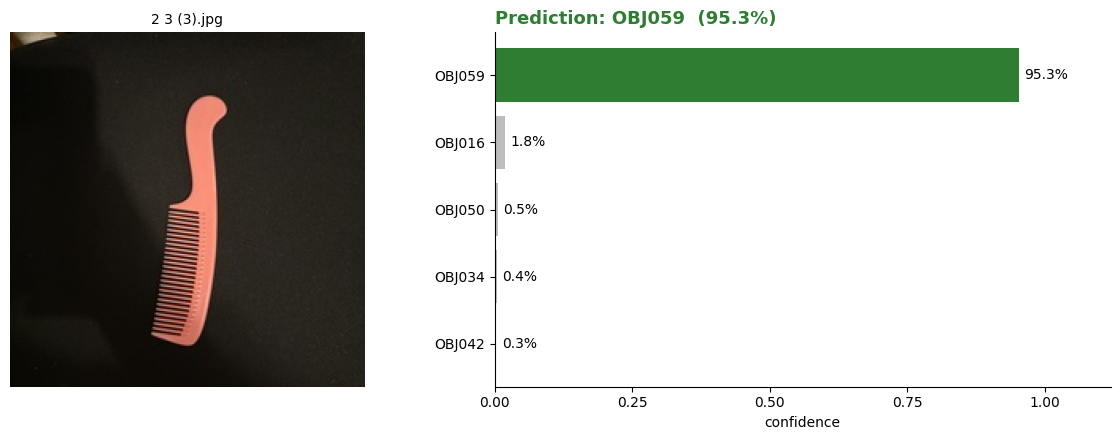

2 3 (3).jpg: OBJ059 (95.3%)


In [28]:
# ============ UPLOAD & PREDICT: run, click "Choose Files", pick one or more images ============
if not IN_COLAB:
    print("Not running in Colab: use the Backup cell below with a file or folder path.")
else:
    uploaded = colab_files.upload()
    for fname, data in uploaded.items():
        try:
            img = load_image(io.BytesIO(data))
        except Exception as e:
            print(f"Could not open {fname}: {e}")
            continue
        run_on(img, title=fname)